# 00. Stage 1 overview / Обзор итогов этапа 1

**EN.** This notebook only *reads* the tables produced in stage 1 (`reports/data_audit/`) and explains them. Nothing is recomputed. It is a reminder of what data we have before we start selecting features.

**RU.** Этот ноутбук только *читает* таблицы этапа 1 (`reports/data_audit/`) и поясняет их. Ничего не пересчитывается. Это напоминание о том, какие у нас данные, перед отбором признаков.

**Task / Задача.**
- **Y1 — early default / ранний дефолт:** a loan that is current at date *t* (0 days past due, DPD = 0) and has never been in default before *t* reaches 90+ DPD or is liquidated within the next 12 months (the first default of the loan). / Кредит без просрочки на дату *t* (DPD = 0), ни разу не бывший в дефолте до *t*, уходит в просрочку 90+ дней или ликвидируется в течение 12 месяцев (первый дефолт кредита).

**EN. Population and candidates.** Only loans current at *t* are in the Y1 population, so the model has to warn before any delinquency is visible: loans 1–2 months late at *t* were 0.3–0.8 % of observations but 38–46 % of Y1 events. For the same reason the 10 delinquency-history features (`dpd`, `dpd_max_6m`, `dpd_max_12m`, `dpd_mean_12m`, `n_30p_6m`, `n_30p_12m`, `n_60p_12m`, `n_cure_12m`, `months_since_30p`, `ever_30p`) are not candidates; 59 candidates remain. **Only the first default counts:** a loan that was already in default (90+ DPD) before *t* and has since cured is excluded from the month of its first default on (`exclude_after_default` in `configs/data.yaml`; first-default months in `data/processed/default_history.parquet`). Such repeat defaults are easy to predict (the loan already has a default history), while the early-warning question is about loans that look healthy. The panel files were built with DPD 0–2 (40,593,542 observations); the population is narrowed when the panel is read (39,009,344 observations). All stage-1 audit tables read below (events, PSI, the leakage check) are computed on this population; LGD uses all liquidations and does not depend on it.

**RU. Популяция и кандидаты.** В популяцию Y1 входят только кредиты без просрочки на *t*: модель должна предупреждать до того, как просрочка станет видна. Кредиты с просрочкой 1–2 мес. на *t* давали 0,3–0,8 % наблюдений, но 38–46 % событий Y1. По той же причине 10 признаков истории просрочек (`dpd`, `dpd_max_6m`, `dpd_max_12m`, `dpd_mean_12m`, `n_30p_6m`, `n_30p_12m`, `n_60p_12m`, `n_cure_12m`, `months_since_30p`, `ever_30p`) не входят в кандидаты; кандидатов 59. **Учитывается только первый дефолт:** кредит, который уже был в дефолте (90+ дней) до *t* и потом вылечился, исключается начиная с месяца первого дефолта (`exclude_after_default` в `configs/data.yaml`; месяцы первого дефолта — в `data/processed/default_history.parquet`). Повторный дефолт предсказать легко (у кредита уже есть история дефолта), а задача раннего предупреждения — о кредитах, которые выглядят здоровыми. Файлы панели собраны с DPD 0–2 (40 593 542 наблюдения); популяция сужается при чтении панели (39 009 344 наблюдения). Все таблицы аудита этапа 1 ниже (события, PSI, проверка на утечку) посчитаны на этой популяции; LGD считается по всем ликвидациям и от неё не зависит.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

import json
from xai_ews.paths import DATA_AUDIT_DIR

def read(name):
    return pd.read_csv(DATA_AUDIT_DIR / name)

COLS = ["n_obs", "n_loans", "y1_events", "y1_event_loans", "y1_rate"]

### 0. Data dictionary / Справочник данных

**EN.** Every candidate feature of the panel with its kind of value and unit. The panel row is a *loan* at a quarter-end date *t*; there is no borrower identifier, so everything describes one loan. `static = True`: written once at origination and never updated (borrower, loan terms, property, geography); `False`: changes over time (state at *t*, behaviour over the last 6–12 months, macro series lagged by their publication delay). Kinds: **categorical** — a code or a name without order; **binary** — Y/N in the source or a 0/1 flag built by us; **integer** — a score, months, a count of months; **continuous** — dollars, rates, shares. A *share* is a fraction (−0.02 = −2 %); *p.p.* = percentage points (difference of two percentages). `model_input` = how CatBoost receives the column. The table comes from `xai_ews.data.dictionary` and needs no data.

**RU.** Все признаки-кандидаты панели с типом значения и единицей измерения. Строка панели — *кредит* на конец квартала *t*; номера заёмщика в данных нет, поэтому всё описывает один кредит. `static = True` — записано один раз при выдаче и не обновляется (заёмщик, условия, объект, география); `False` — меняется со временем (состояние на *t*, поведение за последние 6–12 месяцев, макроряды с задержкой публикации). Типы: **категориальный** — код или название без порядка; **бинарный** — Y/N в исходных данных или флаг 0/1, построенный нами; **целое** — баллы, месяцы, число месяцев; **вещественное** — доллары, ставки, доли. *Доля* записана дробью (−0,02 = −2 %); *п.п.* — процентные пункты (разность двух процентов). `model_input` — как признак подаётся в CatBoost. Таблица берётся из `xai_ews.data.dictionary`, данные не нужны.

In [2]:
from xai_ews.data.dictionary import feature_dictionary

fd = feature_dictionary()
pd.crosstab(fd["kind"], fd["static"].map({True: "static", False: "dynamic"}).rename("temporal"), margins=True, margins_name="total")

temporal,dynamic,static,total
kind,,,
binary,2,6,8
categorical,1,12,13
continuous,19,4,23
integer,7,8,15
total,29,30,59


In [3]:
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 70):
    display(fd[["feature", "meaning_ru", "group", "static", "kind", "unit_en", "unit_ru", "values",
                "model_input", "source"]].assign(feature=fd["feature"].str.slice(0, 45)).set_index("feature"))

,meaning_ru,group,static,kind,unit_en,unit_ru,values,model_input,source
feature,,,,,,,,,
borrower_credit_score_at_origination,кредитный рейтинг (FICO) заёмщика при выдаче,borrower,True,integer,points,баллы,300-850,number,Fannie Mae
co_borrower_credit_score_at_origination,"рейтинг созаёмщика (пусто, если его нет)",borrower,True,integer,points,баллы,300-850; empty = no co-borrower,number,Fannie Mae
debt_to_income_dti,"долговая нагрузка: платежи по долгам / доход, %",borrower,True,integer,% of monthly income,% месячного дохода,,number,Fannie Mae
number_of_borrowers,число заёмщиков по кредиту,borrower,True,integer,persons,человек,,number,Fannie Mae
first_time_home_buyer_indicator,покупает жильё впервые (Y/N),borrower,True,binary,code,код,"Y yes, N no, empty = unknown",category,Fannie Mae
original_interest_rate,"ставка по кредиту при выдаче, %",loan,True,continuous,% per year,% годовых,,number,Fannie Mae
original_upb,сумма кредита при выдаче,exposure,True,continuous,US dollars,долл. США,,number,Fannie Mae
original_loan_term,"срок кредита по договору, мес.",loan,True,integer,months,мес.,,number,Fannie Mae
original_loan_to_value_ratio_ltv,"кредит / стоимость жилья при выдаче (LTV), %",loan,True,integer,% of property value,% стоимости жилья,,number,Fannie Mae


**EN. How to read.** 30 of the 59 candidates are static: 29 Fannie Mae origination fields (borrower, loan terms, property, geography, loan amount) and `sato`, the rate spread over the market rate in the month of origination. 29 change over time: 6 are reported by Fannie Mae for month *t* (servicer, current rate, loan age, two remaining terms, current balance), 12 are computed by us from the loan's monthly records up to *t*, 11 come from external series (FHFA house prices, BLS unemployment, Freddie Mac market rate). The delinquency-history features are not in the table because they are not candidates. Codes and names (13 categorical) and Y/N fields are given to CatBoost as categories; 0/1 flags, scores, months, dollars and shares as numbers. The 18 features that entered the final model, with their value ranges on train, are in notebook `02_6_ablation_and_final`, section 7.

**RU. Как читать.** 30 из 59 кандидатов статичны: 29 полей Fannie Mae на дату выдачи (заёмщик, условия кредита, объект, география, сумма кредита) и `sato` — превышение ставки над рыночной в месяц выдачи. 29 меняются со временем: 6 Fannie Mae сообщает в отчёте за месяц *t* (сервисер, текущая ставка, возраст кредита, два остатка срока, текущий ОД), 12 мы считаем сами по помесячным записям кредита до *t*, 11 берутся из внешних рядов (цены на жильё FHFA, безработица BLS, рыночная ставка Freddie Mac). Признаков истории просрочек в таблице нет: они не входят в кандидаты. Коды и названия (13 категориальных) и поля Y/N подаются в CatBoost как категории; флаги 0/1, баллы, месяцы, доллары и доли — как числа. 18 признаков итоговой модели с диапазонами значений на train — в ноутбуке `02_6_ablation_and_final`, раздел 7.

### 1. Events by sample / События по выборкам

**EN.** One row of the panel is a *loan × quarter-end date*. A loan appears at many dates, so we count events two ways: per observation (`y1_events`) and per unique loan (`y1_event_loans`). The train sample here is the **full train** (all loans of the train vintages); validation and test are the 15 % hash sample. **The table is on the current Y1 population (DPD = 0 at *t*, no default before *t*).** The test row is shown only as a stage-1 fact — in stage 2 we never open the test set.

**RU.** Одна строка панели — *кредит × дата конца квартала*. Кредит встречается на многих датах, поэтому события считаются двумя способами: по наблюдениям (`y1_events`) и по уникальным кредитам (`y1_event_loans`). Train здесь — **полный** (все кредиты поколений train); validation и test — 15 %-я хэш-выборка. **Таблица — на текущей популяции Y1 (DPD = 0 на *t*, без дефолта до *t*).** Строка test показана только как факт этапа 1: на этапе 2 test не открывается.

In [4]:
full = read("events_train_full.csv").assign(sample="train (full)")
splits = read("events_by_split.csv").dropna(subset=["split_main"])
splits = splits.assign(sample=splits["split_main"] + " (15 % sample)")
pd.concat([full, splits])[["sample", *COLS]].set_index("sample")

,n_obs,n_loans,y1_events,y1_event_loans,y1_rate
sample,,,,,
train (full),11405213,2033347,14062,7068,0.0012
test (15 % sample),4111592,1165299,8661,4966,0.0021
train (15 % sample),1710613,304852,2089,1037,0.0012
validation (15 % sample),2010979,629463,6472,3818,0.0032


**EN. How to read.** `y1_rate` is the share of observations with an event. Full train has 11,405,213 observations of 2,033,347 loans and 14,062 events on **7,068** loans (0.12 %). A defaulting loan is positive on about 2 snapshots on average (2.0 in train, 1.7 in validation and test; after its first missed payment it leaves the population and, after its first default, never returns), so the *effective* number of independent events is the number of loans with events: 7,068 — above the 5,000 threshold of the methodology; the 15 % train alone would give only 1,037 such loans (2,089 events). Validation: 2,010,979 observations and 6,472 events on 3,818 loans (0.32 %); without the hurricane rows 1,854,380 observations and 3,706 events on 2,259 loans (0.20 %, section 3). Test: 4,111,592 observations and 8,661 events on 4,966 loans (0.21 %). Validation and test have a higher event rate than train: the period changed, which is why we recalibrate PD on validation in stage 3. Compared with the earlier population (DPD 0–2: 23,971 events on 8,694 loans in full train), the two restrictions (current at *t*, no default before *t*) remove only 0.41 % of the train observations but 41 % of its events and 19 % of the loans with events (validation without the hurricane rows: 0.8 % of observations and 48 % of events; test: 1.2 % and 53 %).

**RU. Как читать.** `y1_rate` — доля наблюдений с событием. В полном train 11 405 213 наблюдений 2 033 347 кредитов и 14 062 события на **7 068** кредитах (0,12 %). Дефолтный кредит в среднем положителен примерно на 2 снимках (2,0 в train, 1,7 в validation и test; после первой просрочки он выходит из популяции, а после первого дефолта в неё уже не возвращается), поэтому *эффективное* число независимых событий — число кредитов с событием: 7 068, это больше порога 5 тыс. из методологии; один 15 %-й train дал бы только 1 037 таких кредитов (2 089 событий). Validation: 2 010 979 наблюдений и 6 472 события на 3 818 кредитах (0,32 %); без наблюдений урагана — 1 854 380 наблюдений и 3 706 событий на 2 259 кредитах (0,20 %, раздел 3). Test: 4 111 592 наблюдения и 8 661 событие на 4 966 кредитах (0,21 %). В validation и test доля событий выше, чем в train: изменился период, поэтому на этапе 3 PD перекалибруется на validation. По сравнению с прежней популяцией (DPD 0–2: в полном train 23 971 событие на 8 694 кредитах) два ограничения (без просрочки на *t*, без дефолта до *t*) убирают всего 0,41 % наблюдений train, но 41 % его событий и 19 % кредитов с событием (validation без наблюдений урагана — 0,8 % наблюдений и 48 % событий, test — 1,2 % и 53 %).

### 2. Events by year / События по годам

**EN.** The event rate over observation years 2006–2025 for the 15 % sample (all vintages, Y1 population: loans current at *t* and never in default before *t*). Grey areas are the stress periods (2007–2010 crisis, COVID); our train/validation years 2013–2017 are calm.

**RU.** Доля событий по годам наблюдения 2006–2025 на 15 %-й выборке (все поколения, популяция Y1 — кредиты без просрочки на *t*, не бывшие в дефолте до *t*). Серым — стресс-периоды (кризис 2007–2010, COVID); наши годы train/validation (2013–2017) — спокойные.

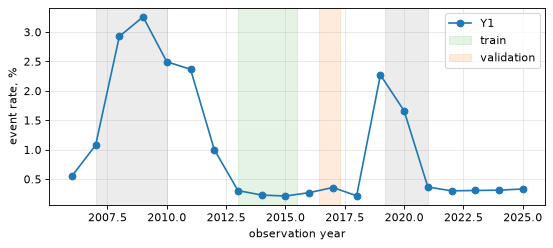

In [5]:
by_year = read("events_by_split_year.csv").groupby("obs_year")[["n_obs", "y1_events"]].sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(by_year.index, 100 * by_year["y1_events"] / by_year["n_obs"], marker="o", label="Y1")
for a, b in [(2007, 2010), (2019.2, 2021)]:
    ax.axvspan(a, b, color="grey", alpha=0.15)
ax.axvspan(2013, 2015.5, color="tab:green", alpha=0.12, label="train")
ax.axvspan(2016.4, 2017.3, color="tab:orange", alpha=0.15, label="validation")
ax.set_ylabel("event rate, %"); ax.set_xlabel("observation year"); ax.legend(); plt.show()

**EN. How to read.** Default rates were 2.4–3.3 % in the 2008–2011 crisis and 1.7–2.3 % in 2019–2020 (label windows covering COVID), and drop to 0.2–0.4 % in 2013–2018 (all observations of each year, not only the train and validation dates). A model trained on calm years will under-predict risk in a crisis, which is why crisis and COVID periods are kept for stress tests only and never used for training. In the earlier population (DPD 0–2) the levels were higher (4–5 % in the crisis, about 2.7 % in 2019–2020, 0.5–0.9 % in 2013–2018), but the shape of the curve is the same.

**RU. Как читать.** В кризис 2008–2011 гг. доля дефолтов 2,4–3,3 %, в 2019–2020 гг. (окна меток захватывают COVID) — 1,7–2,3 %, в 2013–2018 гг. — 0,2–0,4 % (все наблюдения года, а не только даты train и validation). Модель, обученная на спокойных годах, занизит риск в кризис, поэтому кризис и COVID оставлены только для стресс-тестов и в обучение не идут. В прежней популяции (DPD 0–2) уровни были выше (4–5 % в кризис, около 2,7 % в 2019–2020 гг., 0,5–0,9 % в 2013–2018 гг.), но форма кривой та же.

### 3. 2017 hurricanes in validation / Ураганы 2017 г. в validation

**EN.** Label windows of the validation dates 2016-12 and 2017-03 contain hurricanes Harvey, Irma and Maria. In TX, FL, PR and VI the event rate at these dates is 8–9 times that of the other states (1.58–1.93 % against 0.19–0.21 %). These rows are excluded from validation in stage 2 as well; the results with them are shown as a sensitivity check.

**RU.** Окна меток дат validation 2016-12 и 2017-03 захватывают ураганы Харви, Ирма и Мария. В TX, FL, PR и VI доля событий на этих датах в 8–9 раз выше, чем в остальных штатах (1,58–1,93 % против 0,19–0,21 %). На этапе 2 эти наблюдения тоже исключаются из validation; результаты с ними — проверка чувствительности.

In [6]:
read("events_validation_with_without_hurricanes.csv").set_index("validation_set")[COLS]

,n_obs,n_loans,y1_events,y1_event_loans,y1_rate
validation_set,,,,,
all,2010979,629463,6472,3818,0.0032
without_hurricane_rows,1854380,610679,3706,2259,0.0020


**EN. How to read.** Without the flagged rows validation keeps 92 % of observations (2,010,979 → 1,854,380) but only 57 % of Y1 events (6,472 → 3,706) and 59 % of the loans with events (3,818 → 2,259); the event rate falls from 0.32 % to 0.20 %. The 156,599 flagged rows have an event rate of 1.77 %, about 9 times the rest. In the earlier population (DPD 0–2) these rows carried 31 % of the validation events, now 43 %: hurricane defaults come mostly from loans that were current before the storm, so narrowing the population removed few of them. A feature that "predicts" hurricanes (e.g. the state) would look stronger with these rows than it is.

**RU. Как читать.** Без отмеченных наблюдений в validation остаётся 92 % наблюдений (2 010 979 → 1 854 380), но только 57 % событий Y1 (6 472 → 3 706) и 59 % кредитов с событием (3 818 → 2 259); доля событий падает с 0,32 % до 0,20 %. В 156 599 отмеченных наблюдениях доля событий 1,77 %, примерно в 9 раз выше, чем в остальных. В прежней популяции (DPD 0–2) на эти наблюдения приходился 31 % событий validation, теперь 43 %: дефолты из-за ураганов в основном у кредитов, которые до урагана платили вовремя, поэтому сужение популяции убрало их мало. Признак, который «угадывает» ураганы (например, штат), с этими строками выглядел бы сильнее, чем он есть.

### 4. LGD (loss given default) / LGD — доля потерь при дефолте

**EN.** LGD is not a feature, but it is part of the expected loss EL = PD × LGD × EAD used later. Base variant: gross of mortgage insurance, discounted at the note rate; segments = mark-to-market LTV at default × judicial state.

**RU.** LGD — не признак, но входит в ожидаемый убыток EL = PD × LGD × EAD, который используется дальше. Базовый вариант: до ипотечного страхования, с дисконтированием по ставке кредита; сегменты — текущий LTV при дефолте × судебный штат.

In [7]:
lgd = read("lgd_variants.csv").query("variant == 'base'")
lgd.pivot_table(index="mtm_ltv_buckets", columns="judicial", values="lgd_mean").reindex(
    ["<60", "60-80", "80-90", "90-100", "100-120", "120+"]).rename(columns={False: "non-judicial", True: "judicial"})

judicial,non-judicial,judicial
mtm_ltv_buckets,,
<60,0.3200,0.4889
60-80,0.3987,0.5198
80-90,0.4225,0.5265
90-100,0.4370,0.5316
100-120,0.4732,0.5554
120+,0.5136,0.5795


**EN. How to read.** LGD rises with LTV (less collateral per dollar of debt) and is 7–17 p.p. higher in judicial states, where foreclosure takes 7–10 months longer.

**RU. Как читать.** LGD растёт с LTV (меньше залога на доллар долга) и на 7–17 п.п. выше в судебных штатах, где изъятие длится на 7–10 месяцев дольше.

### 5. Distribution shift (PSI) / Сдвиг распределений (PSI)

**EN.** PSI — population stability index — measures how much the distribution of a feature changed between train and validation: PSI = Σ (share_new − share_train) · ln(share_new / share_train) over bins. < 0.1 stable, 0.1–0.25 moderate, > 0.25 large shift. Stage 1 computed it on decile bins; in stage 2 (notebook 02_3) it is recomputed on the WoE bins.

**RU.** PSI — индекс стабильности популяции — показывает, насколько изменилось распределение признака между train и validation: PSI = Σ (доля_new − доля_train) · ln(доля_new / доля_train) по корзинам. < 0,1 — стабильно, 0,1–0,25 — умеренный сдвиг, > 0,25 — сильный. На этапе 1 PSI считался по децилям; на этапе 2 (ноутбук 02_3) он пересчитывается по WoE-корзинам.

In [8]:
psi = read("psi_train_vs_other.csv")[["feature", "train->validation"]].sort_values("train->validation", ascending=False)
print("features with PSI > 0.25:", (psi["train->validation"] > 0.25).sum(), "of", len(psi))
psi.head(12).set_index("feature")

features with PSI > 0.25: 9 of 59


,train->validation
feature,
unemployment,3.2625
unemployment_chg_12m,3.1525
unemployment_chg_6m,1.6160
servicer_name,0.8086
unemployment_rel_us,0.5636
hpi_chg_12m,0.4138
unemployment_chg_12m_rel_us,0.4113
hpi_chg_since_orig,0.3671
seller_name,0.3227


**EN. How to read.** The table lists the 59 current candidates; PSI is computed on a sample of the current population (up to 600,000 observations per sample). Raw unemployment and its changes shift enormously (PSI 1.6–3.3) because the whole country's labour market improved between 2013 and 2017 — the feature mostly encodes the calendar. The relative versions (state minus US) shift much less. Servicer and seller names also drift (portfolio transfers, market shares). These are the main suspects for the stability step.

**RU. Как читать.** В таблице — 59 текущих кандидатов; PSI считается по подвыборке текущей популяции (до 600 тыс. наблюдений на выборку). Безработица и её изменения сдвигаются очень сильно (PSI 1,6–3,3): рынок труда всей страны улучшился с 2013 по 2017 г., и признак в основном кодирует календарь. Относительные версии (штат минус США) сдвигаются намного меньше. Названия сервисера и продавца тоже дрейфуют (передача портфелей, доли рынка). Это главные кандидаты на исключение по стабильности.

### 6. Leakage check / Проверка на утечку

**EN.** A quick CatBoost on all 59 candidates (stage 1): current population (DPD = 0, no default before *t*), full train with negatives sampled at r = 0.2 and weights 1/r, validation = the 15 % sample with the hurricane rows. If validation AUC were ≥ 0.97 we would suspect that some feature contains future information (leakage).

**RU.** Быстрый CatBoost на всех 59 кандидатах (этап 1): текущая популяция (DPD = 0, без дефолта до *t*), полный train с отрицательными при r = 0,2 и весами 1/r, validation — 15 %-я выборка вместе с наблюдениями урагана. Если бы AUC на validation был ≥ 0,97, это указывало бы на утечку — признак с информацией из будущего.

In [9]:
lc = json.loads((DATA_AUDIT_DIR / "leakage_check.json").read_text())
pd.DataFrame({t: {"train rows": v["train_rows"], "train events": v["train_events"],
                  "validation AUC": v["validation_auc"],
                  "best single feature": v["top_single_feature_auc"][0][0],
                  "its AUC": v["top_single_feature_auc"][0][1]} for t, v in lc.items() if t == "y1"})

,y1
train rows,2294292
train events,14062
validation AUC,0.8195
best single feature,borrower_credit_score_at_origination
its AUC,0.7738


**EN. Conclusion.** AUC 0.820 — far below 0.97, and no single feature comes close to the model (the best, credit score at origination, gives 0.774): no leakage. The earlier run on DPD 0–2 with 69 candidates, including the delinquency history, gave 0.891; the drop is expected, because loans with visible delinquency and the features that describe it are gone and the task is harder. Validation here includes the hurricane rows; without them the stage-2 CatBoost on the same 59 candidates gives 0.851 (notebook `02_6`). Stage 2 starts from these 59 candidates and selects 18.

**RU. Вывод.** AUC 0,820 — далеко от 0,97, и ни один признак сам по себе не приближается к модели (лучший, рейтинг при выдаче, даёт 0,774): утечки нет. Прежний прогон на DPD 0–2 с 69 кандидатами, включая историю просрочек, давал 0,891; снижение ожидаемо: ушли кредиты с уже видимой просрочкой и признаки, которые её описывают, и задача стала сложнее. Validation здесь включает наблюдения урагана; без них CatBoost этапа 2 на тех же 59 кандидатах даёт 0,851 (ноутбук `02_6`). Этап 2 начинается с этих 59 кандидатов и отбирает 18.